# Baseline: diagnosing an error-recognition model with metric tables

This notebook gives you the same facts as StepLens, as pandas tables. Each step of every
recording is one row; the model gives each step a score; a step is flagged as an error
when its score is above the model's threshold (chosen on the validation steps).

**Your task (15 minutes):** find the model's main failure modes — groups of steps
(error category, recipe, person, kitchen, step duration, position in the recipe, or a
combination) where it misses more errors than overall, or raises more false alarms.
Write each finding on the task sheet with its numbers. Run the cells top to bottom,
then edit the slicing cells near the end as you like.

In [1]:
import pandas as pd
pd.set_option("display.max_rows", 200, "display.width", 160)

MODEL = "omnivore_mlp_video_step_lr1e-4"          # the model you are diagnosing
OTHER = "slowfast_mlp_video_step_lr1e-4"          # a second model for comparison
PHASE = "test"                                     # evaluate on these steps
HOLDOUT = "val"                                    # confirm findings on these steps

CATS = ["preparation", "measurement", "order", "timing", "technique", "temperature"]

steps = pd.read_csv("data/steps.csv")
def load(model):
    pred = pd.read_csv(f"data/pred_{model}.csv")
    d = steps.merge(pred, on="step_key")
    val = d[d.phase == "val"]
    # balanced threshold: maximizes TPR - FPR on the validation steps
    best, best_t = -1, 0.5
    for t in [i / 100 for i in range(1, 100)]:
        pos = val.score > t
        tpr = pos[val.has_errors].mean(); fpr = pos[~val.has_errors].mean()
        if tpr - fpr > best: best, best_t = tpr - fpr, t
    d["flagged"] = d.score > best_t
    d["missed"] = d.has_errors & ~d.flagged
    d["false_alarm"] = ~d.has_errors & d.flagged
    return d, best_t

df, THRESHOLD = load(MODEL)
other, OTHER_THRESHOLD = load(OTHER)
test = df[df.phase == PHASE]
hold = df[df.phase == HOLDOUT]
print(f"{MODEL}: threshold {THRESHOLD:.2f}; {len(test)} {PHASE} steps, {int(test.has_errors.sum())} with errors")

omnivore_mlp_video_step_lr1e-4: threshold 0.07; 799 test steps, 252 with errors


## 1. Overall performance on the test steps

In [2]:
def summary(d):
    err, norm = d[d.has_errors], d[~d.has_errors]
    return pd.Series({"steps": len(d), "error steps": len(err), "recall": err.flagged.mean(),
                      "miss rate": 1 - err.flagged.mean(), "false alarm rate": norm.flagged.mean(),
                      "precision": err.flagged.sum() / max(1, d.flagged.sum()), "accuracy": (d.flagged == d.has_errors).mean()})
pd.DataFrame({PHASE: summary(test), HOLDOUT: summary(hold)}).round(3)

,test,val
steps,799.000,776.000
error steps,252.000,250.000
recall,0.738,0.656
miss rate,0.262,0.344
false alarm rate,0.406,0.439
precision,0.456,0.415
accuracy,0.640,0.591


## 2. By error category (a step can carry several categories; missing steps are never scored)

In [3]:
rows = []
for c in CATS:
    m = test[test[f"err_{c}"]]
    h = hold[hold[f"err_{c}"]]
    rows.append({"category": c, "error steps": len(m), "missed": int(m.missed.sum()), "miss rate": m.missed.mean(),
                 f"miss rate ({HOLDOUT})": h.missed.mean(), f"n ({HOLDOUT})": len(h)})
pd.DataFrame(rows).round(3)

,category,error steps,missed,miss rate,miss rate (val),n (val)
0,preparation,51,14,0.275,0.371,62
1,measurement,41,11,0.268,0.435,23
2,order,143,40,0.280,0.263,76
3,timing,36,9,0.250,0.289,38
4,technique,62,17,0.274,0.341,88
5,temperature,9,2,0.222,0.375,8


## 3. By recipe, person, kitchen, step duration and position

Compare each row with the overall miss rate from section 1. `holdout` columns show the same group on the hold-out steps.

In [4]:
OVERALL_MISS = test[test.has_errors].missed.mean()
OVERALL_FA = test[~test.has_errors].false_alarm.mean()

def by(cols, min_errors=10, d=test, h=hold):
    err = d[d.has_errors].groupby(cols).agg(error_steps=("missed", "size"), missed=("missed", "sum"), miss_rate=("missed", "mean"))
    fa = d[~d.has_errors].groupby(cols).agg(normal_steps=("false_alarm", "size"), false_alarm_rate=("false_alarm", "mean"))
    herr = h[h.has_errors].groupby(cols).agg(holdout_error_steps=("missed", "size"), holdout_miss_rate=("missed", "mean"))
    out = err.join(fa, how="left").join(herr, how="left")
    out["miss_vs_overall"] = out.miss_rate - OVERALL_MISS
    out["fa_vs_overall"] = out.false_alarm_rate - OVERALL_FA
    return out[out.error_steps >= min_errors].sort_values("miss_rate", ascending=False).round(3)

print(f"overall miss rate {OVERALL_MISS:.3f}, overall false-alarm rate {OVERALL_FA:.3f}")
by("activity_name")

overall miss rate 0.262, overall false-alarm rate 0.406


,error_steps,missed,miss_rate,normal_steps,false_alarm_rate,holdout_error_steps,holdout_miss_rate,miss_vs_overall,fa_vs_overall
activity_name,,,,,,,,,
Spicy Tuna Avocado Wraps,13,7,0.538,34,0.235,12,0.417,0.277,-0.171
Mug Cake,12,5,0.417,39,0.410,11,0.636,0.155,0.004
Cucumber Raita,11,4,0.364,25,0.360,8,0.375,0.102,-0.046
Blender Banana Pancakes,13,4,0.308,23,0.348,13,0.385,0.046,-0.058
Pinwheels,11,3,0.273,18,0.278,10,0.200,0.011,-0.128
Broccoli Stir Fry,13,3,0.231,48,0.667,8,0.375,-0.031,0.261
Herb Omelet with Fried Tomatoes,13,3,0.231,20,0.350,13,0.385,-0.031,-0.056
Tomato Chutney,20,4,0.200,22,0.545,15,0.133,-0.062,0.140
Sauted Mushrooms,12,2,0.167,21,0.571,13,0.231,-0.095,0.166


In [5]:
by("person_id")

,error_steps,missed,miss_rate,normal_steps,false_alarm_rate,holdout_error_steps,holdout_miss_rate,miss_vs_overall,fa_vs_overall
person_id,,,,,,,,,
2,16,11,0.688,50,0.320,17,0.588,0.426,-0.086
6,29,12,0.414,64,0.391,24,0.500,0.152,-0.015
4,50,14,0.280,84,0.429,42,0.333,0.018,0.023
7,25,6,0.240,61,0.311,31,0.387,-0.022,-0.094
3,37,7,0.189,78,0.333,36,0.222,-0.073,-0.073
5,32,6,0.188,54,0.407,25,0.160,-0.074,0.002
1,49,8,0.163,94,0.468,49,0.286,-0.099,0.062
8,14,2,0.143,62,0.548,26,0.462,-0.119,0.143


In [6]:
by("environment_id")

,error_steps,missed,miss_rate,normal_steps,false_alarm_rate,holdout_error_steps,holdout_miss_rate,miss_vs_overall,fa_vs_overall
environment_id,,,,,,,,,
2,53,32,0.604,103,0.233,50,0.620,0.342,-0.173
5,43,15,0.349,108,0.269,47,0.511,0.087,-0.137
7,28,4,0.143,82,0.463,33,0.303,-0.119,0.058
1,60,7,0.117,75,0.720,53,0.113,-0.145,0.314
6,42,2,0.048,89,0.596,41,0.146,-0.214,0.190


In [7]:
by("duration_bucket")

,error_steps,missed,miss_rate,normal_steps,false_alarm_rate,holdout_error_steps,holdout_miss_rate,miss_vs_overall,fa_vs_overall
duration_bucket,,,,,,,,,
15-30s,62,23,0.371,138,0.377,65,0.308,0.109,-0.029
<15s,54,15,0.278,133,0.421,59,0.356,0.016,0.015
30-60s,77,18,0.234,130,0.369,50,0.360,-0.028,-0.037
60-120s,35,7,0.200,76,0.421,49,0.408,-0.062,0.015
>120s,24,3,0.125,70,0.486,27,0.259,-0.137,0.080


In [8]:
by("position_bucket")

,error_steps,missed,miss_rate,normal_steps,false_alarm_rate,holdout_error_steps,holdout_miss_rate,miss_vs_overall,fa_vs_overall
position_bucket,,,,,,,,,
Q4,123,36,0.293,434,0.382,197,0.330,0.031,-0.023
Q3,113,27,0.239,102,0.480,39,0.359,-0.023,0.075
Q2,16,3,0.188,10,0.600,10,0.400,-0.074,0.194


## 4. Two-way slices

Edit the column list. Combinations with fewer than `min_errors` error steps are hidden.

In [9]:
by(["environment_id", "position_bucket"], min_errors=10).head(15)

error_steps  missed  miss_rate  normal_steps  false_alarm_rate  holdout_error_steps  holdout_miss_rate  miss_vs_overall  \
environment_id position_bucket                                                                                                                            
2              Q4                        31      22      0.710          80.0             0.212                 43.0              0.605            0.448   
               Q3                        18       8      0.444          21.0             0.238                  6.0              0.667            0.183   
5              Q4                        16       7      0.438          81.0             0.247                 32.0              0.469            0.176   
               Q3                        24       7      0.292          23.0             0.348                 10.0              0.600            0.030   
7              Q3                        14       3      0.214          12.0             0.500                  6.0              0.333           -0.048   
1              Q3                        26       5      0.192          19.0             0.789                  7.0              0.000           -0.070   
7              Q4                        13       1      0.077          68.0             0.441                 26.0              0.308           -0.185   
1              Q4                        30       2      0.067          56.0             0.696                 44.0              0.114           -0.195   
6              Q3                        16       1      0.062          15.0             0.733                  5.0              0.200           -0.199   
               Q4                        23       1      0.043          73.0             0.562                 32.0              0.125           -0.218   

                                fa_vs_overall  
environment_id position_bucket                 
2              Q4                      -0.193  
               Q3                      -0.168  
5              Q4                      -0.159  
               Q3                      -0.058  
7              Q3                       0.094  
1              Q3                       0.384  
7              Q4                       0.035  
1              Q4                       0.291  
6              Q3                       0.327  
               Q4                       0.156

In [10]:
by(["person_id", "environment_id"], min_errors=10).head(15)

error_steps  missed  miss_rate  normal_steps  false_alarm_rate  holdout_error_steps  holdout_miss_rate  miss_vs_overall  \
person_id environment_id                                                                                                                            
4         2                        11       6      0.545          16.0             0.250                    8              0.375            0.284   
1         2                        11       5      0.455          17.0             0.294                   10              0.500            0.193   
          7                        11       1      0.091          17.0             0.588                   10              0.300           -0.171   
          1                        12       1      0.083          14.0             0.571                   15              0.133           -0.179   
          6                        10       0      0.000          18.0             0.944                   10              0.100           -0.262   
3         1                        14       0      0.000           9.0             0.778                   10              0.000           -0.262   
          6                        10       0      0.000          18.0             0.444                   10              0.000           -0.262   

                          fa_vs_overall  
person_id environment_id                 
4         2                      -0.156  
1         2                      -0.112  
          7                       0.182  
          1                       0.166  
          6                       0.539  
3         1                       0.372  
          6                       0.039

### A category inside a group

Restrict to one category first, then group.

In [11]:
CATEGORY = "order"
sub = test[~test.has_errors | test[f"err_{CATEGORY}"]]
subh = hold[~hold.has_errors | hold[f"err_{CATEGORY}"]]
by("environment_id", min_errors=8, d=sub, h=subh)

,error_steps,missed,miss_rate,normal_steps,false_alarm_rate,holdout_error_steps,holdout_miss_rate,miss_vs_overall,fa_vs_overall
environment_id,,,,,,,,,
2,39,24,0.615,103,0.233,12,0.583,0.353,-0.173
5,15,7,0.467,108,0.269,10,0.600,0.205,-0.137
7,17,2,0.118,82,0.463,10,0.200,-0.144,0.058
1,35,3,0.086,75,0.720,20,0.050,-0.176,0.314
6,23,0,0.000,89,0.596,12,0.083,-0.262,0.190


## 5. Does the other model miss the same errors?

In [12]:
o = other[other.phase == PHASE].set_index("step_key")
t = test.set_index("step_key")
common = t.index.intersection(o.index)
a, b, y = t.loc[common, "flagged"], o.loc[common, "flagged"], t.loc[common, "has_errors"]
rows = []
for c in CATS + ["normal"]:
    m = (~y) if c == "normal" else t.loc[common, f"err_{c}"].astype(bool)
    rows.append({"category": c, "n": int(m.sum()), "both flag": int((a & b & m).sum()), f"{MODEL} only": int((a & ~b & m).sum()),
                 f"{OTHER} only": int((~a & b & m).sum()), "neither": int((~a & ~b & m).sum())})
pd.DataFrame(rows)

,category,n,both flag,omnivore_mlp_video_step_lr1e-4 only,slowfast_mlp_video_step_lr1e-4 only,neither
0,preparation,51,22,15,6,8
1,measurement,41,19,11,7,4
2,order,143,67,36,18,22
3,timing,36,20,7,6,3
4,technique,62,28,17,7,10
5,temperature,9,6,1,2,0
6,normal,547,116,106,76,249


## 6. Look at individual steps

For example, the missed error steps of one recording, with the error descriptions.

In [13]:
rid = test[test.missed].recording_id.value_counts().index[0]
cols = ["recording_id", "activity_name", "person_id", "environment_id", "start_time", "end_time", "duration", "position_idx", "error_list", "score", "flagged"]
df[(df.recording_id == rid)].sort_values("start_time")[cols]

,recording_id,activity_name,person_id,environment_id,start_time,end_time,duration,position_idx,error_list,score,flagged
4296,25_40,Pan Fried Tofu,2,2,158.070286,210.444000,52.373714,0,Measurement Error: Cut into small cubes rather...,0.025769,False
4297,25_40,Pan Fried Tofu,2,2,259.914229,264.766000,4.851771,1,Measurement Error: Use a tbsp instead of a tsp,0.071283,True
4298,25_40,Pan Fried Tofu,2,2,280.070843,291.679000,11.608157,2,NaN,0.084265,True
4299,25_40,Pan Fried Tofu,2,2,304.470954,314.018824,9.547870,3,NaN,0.017860,False
4300,25_40,Pan Fried Tofu,2,2,316.140573,324.992000,8.851427,4,Technique Error: Drop a few tofu cubes while a...,0.101571,True
4301,25_40,Pan Fried Tofu,2,2,335.000000,338.000000,3.000000,5,NaN,0.123399,True
4302,25_40,Pan Fried Tofu,2,2,336.297186,440.141000,103.843814,6,Timing Error: Cook 2 to 3 minutes instead of 5...,0.058822,False
4303,25_40,Pan Fried Tofu,2,2,488.000000,500.000000,12.000000,7,NaN,0.057587,False
4304,25_40,Pan Fried Tofu,2,2,510.000000,524.000000,14.000000,8,NaN,0.051846,False
4305,25_40,Pan Fried Tofu,2,2,528.000000,532.000000,4.000000,9,NaN,0.053142,False


## 7. A few plots (the 'strong baseline' an analyst would make)

Miss rate by each attribute with 95% Wilson intervals, a person × kitchen heat map, and score distributions.

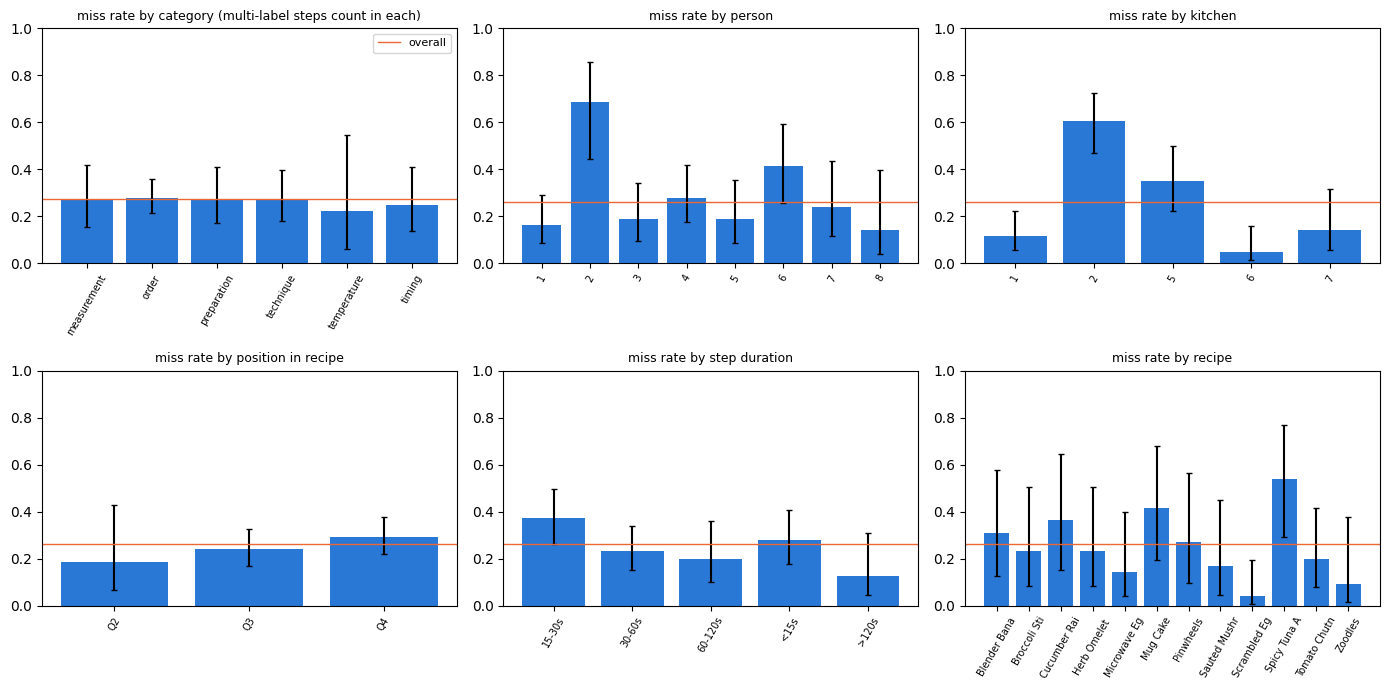

In [14]:
import numpy as np, matplotlib.pyplot as plt
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z*z/n; c = (p + z*z/(2*n)) / d; h = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / d
    return c - h, c + h
def miss_bar(ax, d, col, title, min_errors=10):
    e = d[d.has_errors]
    g = e.groupby(col)["missed"].agg(["sum", "size"]).query("size >= @min_errors")
    rate = g["sum"] / g["size"]
    lo, hi = zip(*[wilson(k, n) for k, n in zip(g["sum"], g["size"])])
    ax.bar(range(len(g)), rate, yerr=[rate - np.array(lo), np.array(hi) - rate], color="#2a78d6", capsize=2)
    ax.axhline(e.missed.mean(), color="#eb6834", lw=1, label="overall")
    ax.set_xticks(range(len(g))); ax.set_xticklabels([str(i)[:12] for i in g.index], rotation=60, fontsize=7)
    ax.set_title(title, fontsize=9); ax.set_ylim(0, 1)
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
cat_long = test[test.has_errors].melt(id_vars=["missed"], value_vars=[f"err_{c}" for c in CATS], var_name="category", value_name="has")
cat_long = cat_long[cat_long.has].assign(category=lambda x: x.category.str[4:], has_errors=True)
miss_bar(axes[0, 0], cat_long, "category", "miss rate by category (multi-label steps count in each)", 5)
miss_bar(axes[0, 1], test, "person_id", "miss rate by person")
miss_bar(axes[0, 2], test, "environment_id", "miss rate by kitchen")
miss_bar(axes[1, 0], test, "position_bucket", "miss rate by position in recipe")
miss_bar(axes[1, 1], test, "duration_bucket", "miss rate by step duration")
miss_bar(axes[1, 2], test, "activity_name", "miss rate by recipe")
axes[0, 0].legend(fontsize=8); fig.tight_layout(); plt.show()

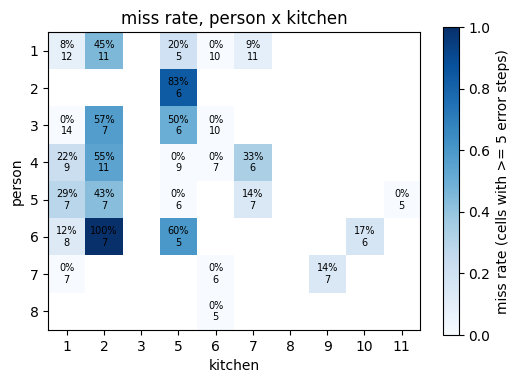

In [15]:
e = test[test.has_errors]
pivot = e.pivot_table(index="person_id", columns="environment_id", values="missed", aggfunc="mean")
counts = e.pivot_table(index="person_id", columns="environment_id", values="missed", aggfunc="size")
fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(pivot.where(counts >= 5), cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(pivot.columns))); ax.set_xticklabels(pivot.columns); ax.set_xlabel("kitchen")
ax.set_yticks(range(len(pivot.index))); ax.set_yticklabels(pivot.index); ax.set_ylabel("person")
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        n = counts.iloc[i, j]
        if n == n and n >= 5: ax.text(j, i, f"{pivot.iloc[i, j]:.0%}\n{int(n)}", ha="center", va="center", fontsize=7)
fig.colorbar(im, label="miss rate (cells with >= 5 error steps)"); ax.set_title("miss rate, person x kitchen"); plt.show()

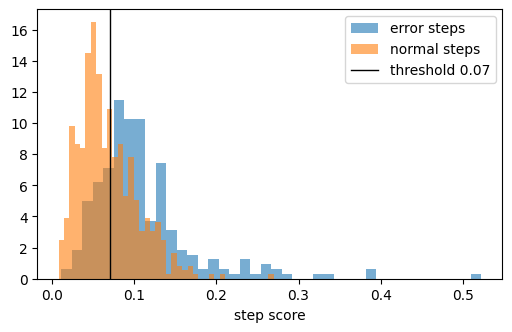

In [16]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(test[test.has_errors].score, bins=40, alpha=0.6, label="error steps", density=True)
ax.hist(test[~test.has_errors].score, bins=40, alpha=0.6, label="normal steps", density=True)
ax.axvline(THRESHOLD, color="k", lw=1, label=f"threshold {THRESHOLD:.2f}"); ax.legend(); ax.set_xlabel("step score"); plt.show()

## Scratch

In [17]:
# your own queries here
